In [3]:
from IPython.display import HTML, display
css_file_path = "../../design/custom.css"
styles = "<link rel='stylesheet' href='%s'>" % css_file_path
display(HTML(styles))

# 3.4 $\quad$ Portfolio Optimization with Short Selling

A **short position** is an investment strategy in which an investor sells an asset they do not currently own, with the obligation to buy it back in the future. The seller expects to profit from a decline in the asset’s price. Consider the following example:

- `A` takes a short position in 500 shares of IBM at `$120` per share, receiving `$60,000`.

- The broker identifies a client, `B`, who is willing to act as the counterparty.

- Client `B` provides the `$60,000`.

- `A` agrees to return the value of the 500 shares to `B` in July.

<img src="https://raw.githubusercontent.com/alfonso-santos/microcredencial-carteras-python/Finance_Technology/Tema_3_Markowitz/imgs/posiciones_cortas_1.jpg" width="500">

- In May, a dividend of `$1` per share is paid.

- `A` must pay the broker `$500` for the 500 shares.

- The broker pays client `B` `$500`.

<img src="https://raw.githubusercontent.com/alfonso-santos/microcredencial-carteras-python/Finance_Technology/Tema_3_Markowitz/imgs/posiciones_cortas_2.jpg" width="500">

- In July, IBM is trading at `$100`, and client `A` closes the short position.

- `A` pays the broker `100 × 500 = $50,000`.

- The broker pays `B` `$50,000`.

- The short position is closed.


<img src="https://raw.githubusercontent.com/alfonso-santos/microcredencial-carteras-python/Finance_Technology/Tema_3_Markowitz/imgs/posiciones_cortas_3.jpg" width="500">

The outcome of the short-selling transaction is as follows:

<img src="../imgs/posiciones_cortas_resultado.jpg">

* Source: Hull (2018)

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cvxpy as cp
import yfinance as yf


plt.style.use('ggplot')

In [5]:
# Date range
start = '2015-01-01'
end = '2019-12-30'

# Assets with positive returns
assets = ['BA', 'BAX', 'BMY', 'CMCSA', 'CNP', 'CPB', 'DE', 'F', 'GE', 'HPQ',
        'JCI', 'JPM','KHC', 'LUV', 'MMC', 'MO', 'NI', 'PCAR', 'PSA', 'SEE',
        'T', 'TGT', 'TMO','TXT', 'VZ', 'ZION']

# Downloading data
prices = yf.download(assets, start = start, end = end)['Close']

[**********************54%*                      ]  14 of 26 completed$SEE: possibly delisted; no timezone found
[**********************65%******                 ]  17 of 26 completed$MMC: possibly delisted; no timezone found
[*********************100%***********************]  26 of 26 completed

2 Failed downloads:
['SEE', 'MMC']: possibly delisted; no timezone found


In [6]:
prices.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1256 entries, 2015-01-02 to 2019-12-27
Data columns (total 26 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   BA      1256 non-null   float64
 1   BAX     1256 non-null   float64
 2   BMY     1256 non-null   float64
 3   CMCSA   1256 non-null   float64
 4   CNP     1256 non-null   float64
 5   CPB     1256 non-null   float64
 6   DE      1256 non-null   float64
 7   F       1256 non-null   float64
 8   GE      1256 non-null   float64
 9   HPQ     1256 non-null   float64
 10  JCI     1256 non-null   float64
 11  JPM     1256 non-null   float64
 12  KHC     1130 non-null   float64
 13  LUV     1256 non-null   float64
 14  MMC     0 non-null      float64
 15  MO      1256 non-null   float64
 16  NI      1256 non-null   float64
 17  PCAR    1256 non-null   float64
 18  PSA     1256 non-null   float64
 19  SEE     0 non-null      float64
 20  T       1256 non-null   float64
 21  TGT     1256 non-null   float6

<Axes: xlabel='Ticker'>

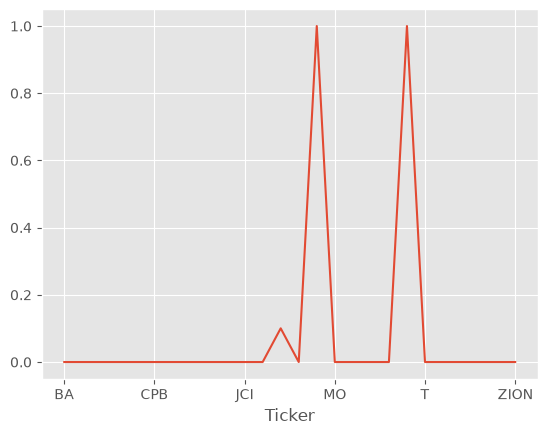

In [7]:
prices.isna().mean().plot()

In [8]:
prices = prices.loc[:, prices.isna().mean() <= 0.10]
assets = prices.columns

In [9]:
# Number of assets
num_act = prices.shape[1]
returns = np.log(prices / prices.shift(1)).dropna()
matriz_cov = returns.cov().to_numpy() # Covariance matrix
retornos_esperados = returns.mean().to_numpy() # Column vector expected return

First, we will construct the Markowitz efficient frontier **without short selling**. We will use a different approach from the risk-aversion formulation. Instead, we will calculate:

1. The minimum-risk portfolio, which identifies the starting point of the efficient frontier.
2. The risk of the asset with the highest expected return, which identifies the ending point of the efficient frontier.
3. Portfolios that maximize expected return for a sequence of risk levels.

In [10]:
# 1. Minimum-risk portfolio

pesos = cp.Variable(num_act)
riesgo = cp.quad_form(pesos, matriz_cov)
ret = retornos_esperados @ pesos
objetivo = cp.Minimize(riesgo)

# Constraints
constraints = [pesos >= 0,
               cp.sum(pesos) == 1
               ]

prob = cp.Problem(objetivo, constraints)

res = prob.solve()

min_ret = ret.value
min_riesgo = np.sqrt(riesgo.value) # This is the starting point of the efficient frontier

In [11]:
# 2. Risk of the highest-return asset
i_activo = np.argmax(retornos_esperados)
max_riesgo = np.sqrt(matriz_cov[i_activo, i_activo])

In [12]:
cp.installed_solvers()

['CLARABEL', 'SCS', 'SCIP', 'SCIPY', 'HIGHS', 'OSQP']

In [13]:
# 3. Vary risk in equally spaced steps

retornos_res = []
riesgos_res = []
for riesgo_objetivo in np.linspace(min_riesgo, max_riesgo, 200):
    pesos = cp.Variable(num_act)
    riesgo = cp.quad_form(pesos, matriz_cov)
    ret = retornos_esperados @ pesos
    objetivo = cp.Maximize(ret)

    # Constraints
    constraints = [pesos >= 0,
                   cp.sum(pesos) == 1,
                   riesgo <= riesgo_objetivo**2
                   ]

    prob = cp.Problem(objetivo, constraints)

    res = prob.solve()
    retornos_res.append(ret.value)
    riesgos_res.append(np.sqrt(riesgo.value))

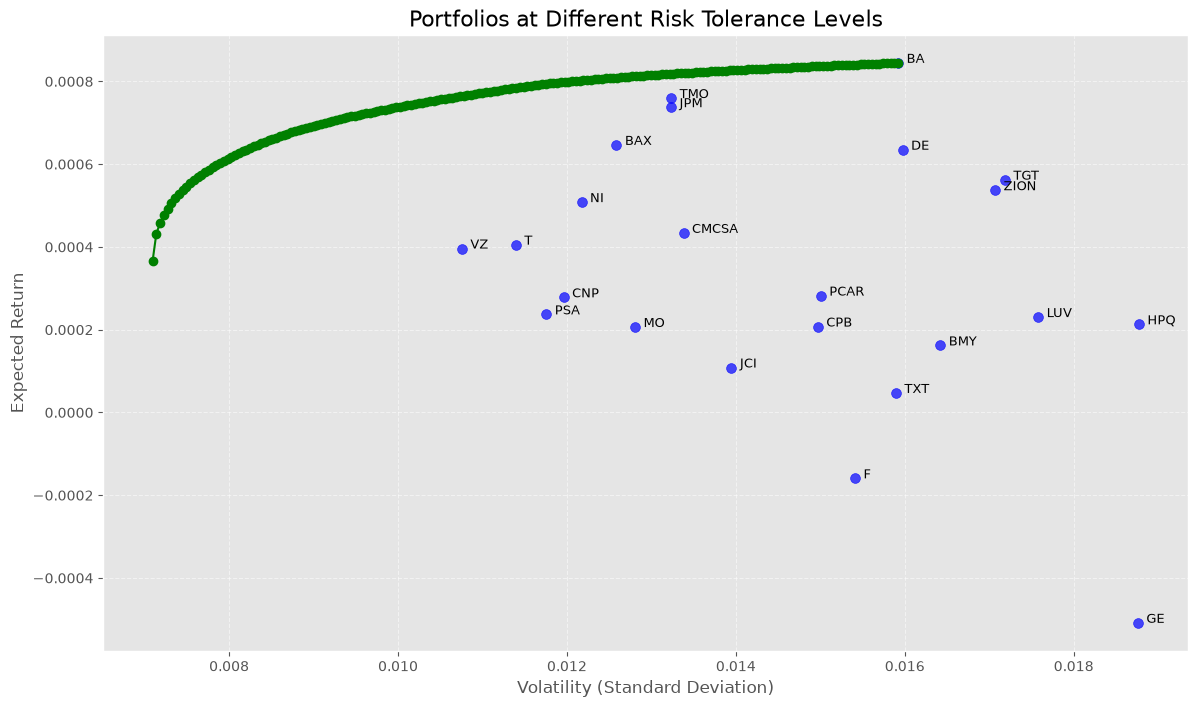

In [14]:
# Set figure size and style
plt.figure(figsize=(14, 8))
plt.style.use('ggplot')

# Individual asset points
plt.scatter(np.sqrt(np.diag(matriz_cov)), retornos_esperados, color='blue', s=50, label='Assets', alpha=0.7)

# Label assets with an offset
desplazamiento_x = 0.0001  # Adjust this value if necessary
desplazamiento_y = 0.00002  # Adjust this value if necessary

for i, asset in enumerate(assets):
    plt.text(np.sqrt(matriz_cov[i, i]) + desplazamiento_x, retornos_esperados[i] , asset, fontsize=9)

plt.plot(riesgos_res, retornos_res, '-o', color='green')#,  alpha=0.3)

# Add chart title and axis labels
plt.title('Portfolios at Different Risk Tolerance Levels', fontsize=16)
plt.xlabel('Volatility (Standard Deviation)', fontsize=12)
plt.ylabel('Expected Return', fontsize=12)

# Place the legend in the best location
#plt.legend(loc='best')

# Display the grid for readability
plt.grid(True, linestyle='--', alpha=0.5)

# Display the chart
plt.show()


## 1. Portfolios with Short Selling

### Portfolios with Short Selling and a Leverage Limit

The objective is to find the maximum-return portfolio subject to a limit on short positions, that is, a maximum leverage constraint. First, let us examine the expected returns of the individual assets:

Text(0.5, 1.0, 'Expected Asset Returns')

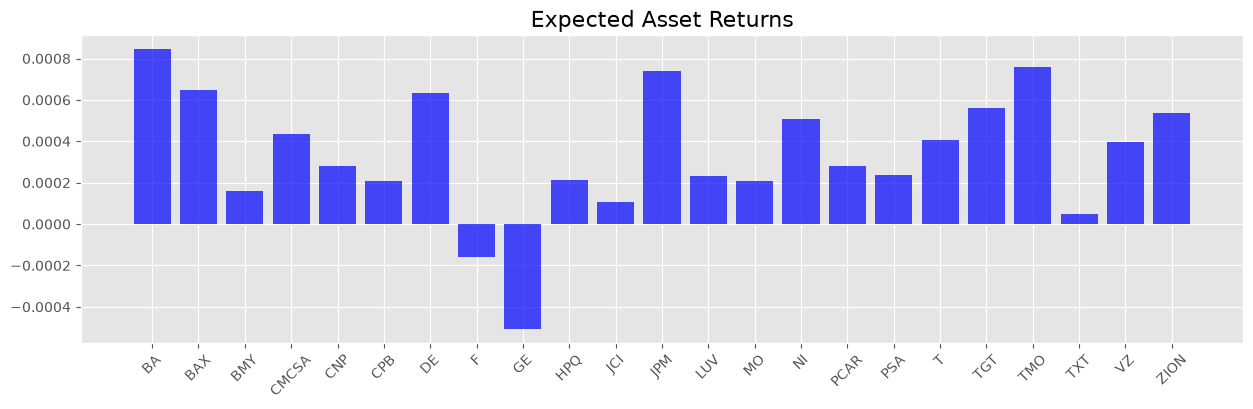

In [15]:
plt.figure(figsize=(15, 4))

plt.bar(range(len(retornos_esperados)), retornos_esperados, color='blue', alpha=0.7)

# Add asset names as x-axis labels
plt.xticks(range(len(assets)), assets, rotation=45)

plt.title('Expected Asset Returns', fontsize=16)

### Exercise 1

As we can see, our investment universe includes assets with negative expected returns. If we **sell these assets short**, we allow negative portfolio weights. Multiplying a negative weight by a negative expected return makes a positive contribution to portfolio expected return. Set a leverage limit of `450%`, meaning that the total absolute amount invested must not exceed `500%`.

In [16]:
# TO DO

Let us plot the weights calculated by the optimizer when short selling is allowed alongside the asset returns shown earlier:

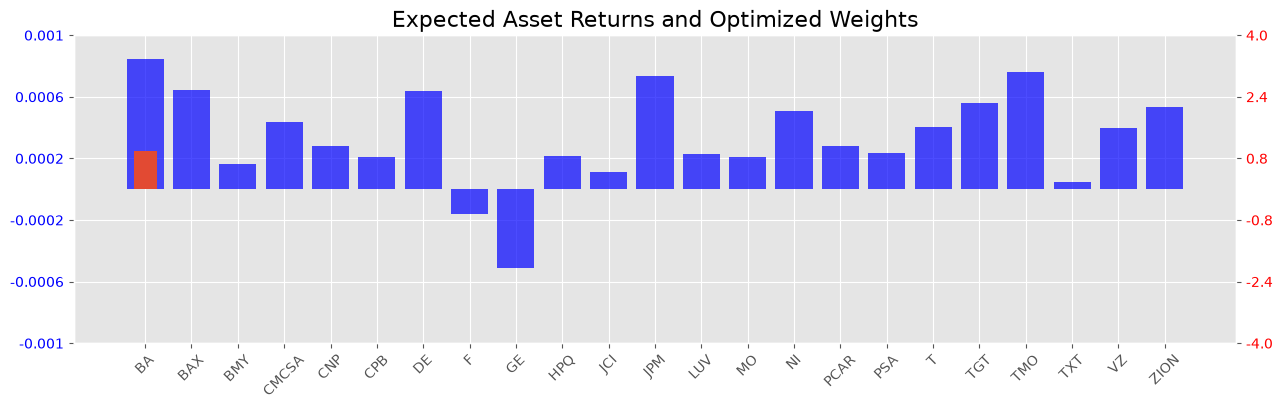

In [17]:
fig, ax = plt.subplots(figsize=(15, 4))

ax.bar(range(len(retornos_esperados)), retornos_esperados, color='blue', alpha=0.7)
ax2 = ax.twinx()
ax2.grid(False)
ax2.bar(range(num_act), pesos.value, width=0.5)

# Add asset names as x-axis labels
ax.set_xticks(range(len(assets)), assets, rotation=45)
ax.set_yticks(np.linspace(-1e-3, 1e-3, 6), np.around(np.linspace(-1e-3, 1e-3, 6), decimals=4), color="blue")
ax2.set_yticks(np.linspace(-4.0, 4.0, 6), np.around(np.linspace(-4.0, 4.0, 6), decimals=4), color="red")

ax.set_title('Expected Asset Returns and Optimized Weights', fontsize=16)

ax.set_ylim(-1e-3, 1e-3)
ax2.set_ylim(-4.0, 4.0)
plt.show()

As the figure shows, without a portfolio-risk constraint, the optimizer chooses the asset with the highest positive expected return (`BA`) and combines it with the asset with the most negative expected return (`GE`).

In [18]:
pesos_ajustados = np.array([np.round(x, 3) if np.abs(x) > 10**-4 else 0  for x in pesos.value])

activos_filtrados = [asset for i, asset in enumerate(assets) if pesos_ajustados[i] > 0]
pesos_filtrados = [x for x in pesos_ajustados if x != 0]

In [19]:
print(f'The assets included in the portfolio are {np.array(assets)[pesos_ajustados != 0].tolist()}')

print(f'The weights that maximize portfolio return are: {pesos_ajustados[pesos_ajustados != 0].round(2)}')

print(f'The returns of assets included in the portfolio are: {retornos_esperados[pesos_ajustados != 0].round(4)}')

The assets included in the portfolio are ['BA']
The weights that maximize portfolio return are: [1.]
The returns of assets included in the portfolio are: [0.0008]


Let us see where the portfolio we have just constructed lies:

In [ ]:
# Set figure size and style
plt.figure(figsize=(10, 6))

# Individual asset points
plt.scatter(np.sqrt(np.diag(matriz_cov)), retornos_esperados, color='blue', s=50, alpha=0.7)


# Label assets with an offset
desplazamiento_x = 0.0001  # Adjust this value if necessary
desplazamiento_y = 0.00003  # Adjust this value if necessary

for i, asset in enumerate(assets):
    plt.text(np.sqrt(matriz_cov[i, i]) + desplazamiento_x, retornos_esperados[i] , asset, fontsize=9)



plt.scatter(np.sqrt(riesgo.value), resultado, color='red', s=100, marker='o')
plt.text(np.sqrt(riesgo.value) - 28*desplazamiento_x, resultado - desplazamiento_y, 'Optimized Portfolio', fontsize=11, color='red')

plt.scatter(riesgos_res, retornos_res, color='green', s=20, marker='o')


# Add chart title and axis labels
plt.title('Portfolios with Short Selling', fontsize=16)
plt.xlabel('Volatility (Standard Deviation)', fontsize=12)
plt.ylabel('Expected Return', fontsize=12)

# Place the legend in the best location
#plt.legend(loc='best')

# Display the grid for readability
plt.grid(True, linestyle='--', alpha=0.5)

# Display the chart
plt.show()

---

### Maximum-Expected-Return Portfolios for Different Risk Tolerances and Short-Selling Leverage Limits

In [ ]:
cortas_max = [1.0, 1.3, 1.5, 1.7, 2.0] # Maximum leverage allowed
resultados_df = pd.DataFrame()
num_sim = 100

In [ ]:
for deuda in cortas_max: #
    riesgos_res_short = np.zeros(num_sim) # Risks
    retornos_res_short = np.zeros(num_sim) # Returns
    gamma_vals = np.logspace(-2, 3, num=num_sim) # Gamma values representing risk aversion

    for i in range(num_sim):
        pesos = cp.Variable(num_act)
        gamma = cp.Parameter(nonneg=True)
        gamma.value = gamma_vals[i]

        ret = retornos_esperados.T @ pesos
        riesgo = cp.quad_form(pesos, matriz_cov)
        objetivo = cp.Maximize(ret - gamma * riesgo)

        constraints = [cp.sum(pesos) == 1,
                       cp.sum(cp.abs(pesos)) <= deuda]
        prob = cp.Problem(objetivo, constraints)
        prob.solve()

        # Check the optimization status
        if prob.status not in ["infeasible", "unbounded"]:
            retornos_res_short[i] = ret.value
            riesgos_res_short[i] = cp.sqrt(riesgo).value
        else:
            print(f"Problem not solved for gamma={gamma.value}: {prob.status}")

    resultados_df[f'riesgo_{deuda}'] = riesgos_res_short
    resultados_df[f'retorno_{deuda}'] = retornos_res_short

In [ ]:
plt.figure(figsize=(10, 6))
plt.style.use('ggplot')

# Individual asset points
plt.scatter(np.sqrt(np.diag(matriz_cov)), retornos_esperados, color='blue', s=50, alpha=0.7)

# Label assets with an offset
desplazamiento_x = 0.0001  # Adjust this value if necessary
desplazamiento_y = 0.00003  # Adjust this value if necessary

for i, asset in enumerate(assets):
    plt.text(np.sqrt(matriz_cov[i, i]) + desplazamiento_x, retornos_esperados[i] , asset, fontsize=9)

for deuda in cortas_max:
    plt.plot(resultados_df[f'riesgo_{deuda}'], resultados_df[f'retorno_{deuda}'], label=f'Short-selling limit: {deuda}')

plt.xlabel('Risk $\sigma$')
plt.ylabel('Expected Return $\mu$')
plt.title('Efficient Frontier for Different Short-Selling Limits')
plt.legend(loc='best')
plt.show()

---

### Exercise 2

Calculate the **maximum-return portfolio** with risk limited to `0.014` and a maximum short position of `20%` in any single asset.

In [ ]:
#TO-DO

In [ ]:
# Store the portfolio to plot it later

max_cortos = np.array([np.sqrt(riesgo.value), ret.value])
max_cortos

In [ ]:
fig, ax = plt.subplots(figsize=(15, 4))

ax.bar(range(len(retornos_esperados)), retornos_esperados, color='blue', alpha=0.7)
ax2 = ax.twinx()
ax2.grid(False)
ax2.bar(range(num_act), pesos.value, width=0.5)

# Add asset names as x-axis labels
ax.set_xticks(range(len(assets)), assets, rotation=45)
ax.set_yticks(np.linspace(-1e-3, 1e-3, 6), np.around(np.linspace(-1e-3, 1e-3, 6), decimals=4), color="blue")
ax.axhline(0.0, color="black")
ax2.set_yticks(np.linspace(-0.7, 0.7, 6), np.around(np.linspace(-0.7, 0.7, 6), decimals=4), color="red")
ax2.axhline(-0.2)

ax.set_title('Expected Asset Returns and Optimized Weights', fontsize=16)

ax.set_ylim(-1e-3, 1e-3)
ax2.set_ylim(-0.7, 0.7)
plt.show()

Now let us calculate the **equivalent portfolio without short selling** so that we can compare the two.

In [ ]:
#TO-DO


In [ ]:
# Store the portfolio to plot it later

max_sin_cortos = np.array([np.sqrt(riesgo.value), ret.value])
max_sin_cortos

In [ ]:
# Set very small weights (below 10**-4) to zero

pesos_ajustados = np.array([np.round(x, 3) if np.abs(x) > 10**-4 else 0  for x in pesos.value])

activos_filtrados = [asset for i, asset in enumerate(assets) if pesos_ajustados[i] > 0]
pesos_filtrados = [x for x in pesos_ajustados if x != 0]

In [ ]:
print(f'The assets included in the portfolio are {np.array(assets)[pesos_ajustados != 0].tolist()}')

print(f'The weights that maximize portfolio return are: {pesos_ajustados[pesos_ajustados != 0].round(2)}')

In [ ]:
# Set figure size and style
plt.figure(figsize=(10, 6))
plt.style.use('ggplot')

# Individual asset points
plt.scatter(np.sqrt(np.diag(matriz_cov)), retornos_esperados, color='blue', s=50, alpha=0.7)


# Label assets with an offset
desplazamiento_x = 0.0001  # Adjust this value if necessary
desplazamiento_y = 0.00003  # Adjust this value if necessary

for i, asset in enumerate(assets):
    plt.text(np.sqrt(matriz_cov[i, i]) + desplazamiento_x, retornos_esperados[i] , asset, fontsize=9)



plt.scatter(max_cortos[0], max_cortos[1], color='red', s=100, marker='o')
plt.text(max_cortos[0] + 2*desplazamiento_x, max_cortos[1] - desplazamiento_y, 'Portfolio with Short Selling', fontsize=11, color='red')

plt.scatter(max_sin_cortos[0], max_sin_cortos[1], color='red', s=100, marker='o')
plt.text(max_sin_cortos[0] , max_sin_cortos[1] + 3 * desplazamiento_y, 'Portfolio without Short Selling', fontsize=11, color='red')

plt.scatter(riesgos_res, retornos_res, color='green', s=20, marker='o')


# Add chart title and axis labels
plt.title('Portfolios with a Risk Limit and a Single-Asset Short-Selling Limit', fontsize=16)
plt.xlabel('Volatility (Standard Deviation)', fontsize=12)
plt.ylabel('Expected Return', fontsize=12)

# Place the legend in the best location
#plt.legend(loc='best')

# Display the grid for readability
plt.grid(True, linestyle='--', alpha=0.5)

# Display the chart
plt.show()